In [28]:
# =============================================================================
# STAT 404: split-plot analysis in R
#
# Model:  Y = mu + G + S + D + R + rho(maze) + A + SD + SA + DA + GA + E
#   Whole plot (maze): G, S, D, S:D, block R;  error = maze within R,G,S,D (rho)
#   Subplot (algorithm): A, S:A, D:A, G:A;     error = E
#   R = replicate / block (one seed per replicate)
#
# Steps: (1) check the model  (2) Box-Cox  (3) transform + recheck
#        (4) ANOVA            (5) interaction plots + algorithm means
# Needs: results.csv in the working directory; package MASS (ships with R)
# =============================================================================
library(MASS)

# ---- 0. Data ----------------------------------------------------------------
dat <- read.csv("results_f.csv")
dat$R    <- factor(dat$rep)                                   # block
dat$G    <- factor(dat$gen_method)                            # whole plot
dat$S    <- factor(dat$size, levels = sort(unique(dat$size))) # 20, 50, 100 in order
dat$D    <- factor(dat$loop_density,
                   levels = sort(unique(dat$loop_density)))   # 0.05, 0.15, 0.30
dat$A    <- factor(dat$algorithm,
                   levels = c("bfs", "dijkstra", "astar", "greedy", "random_walk"))
dat$maze <- factor(dat$maze_id)                               # whole-plot unit
dat$y_raw <- dat$time_s              

In [29]:
stopifnot(all(dat$y_raw > 0))
cat("Runs:", nrow(dat), "| mazes:", nlevels(dat$maze),
    "| censored random-walk runs:", sum(dat$success == 0), "\n")
print(table(dat$R, dat$G))                                    # balance check

# ---- 1. Model checking function ----------------------------------------------
# Subplot residuals: lm(y ~ maze + A + A:S + A:D + A:G). The maze term absorbs all
#   maze-level variation, so residuals = subplot error of the final model (512 df).
# Maze-level residuals: maze means on R + G + S + D + S:D = whole-plot error (120 df).
check_model <- function(y, data, label = "") {
  d <- data; d$y <- y
  fit_sub <- lm(y ~ maze + A + A:S + A:D + A:G, data = d)
  mz      <- aggregate(y ~ maze + R + G + S + D, data = d, FUN = mean)
  fit_wp  <- lm(y ~ R + G + S + D + S:D, data = mz)
  
  r  <- resid(fit_sub); f <- fitted(fit_sub)
  rw <- resid(fit_wp);  fw <- fitted(fit_wp)
  
  op <- par(mfrow = c(2, 3), mar = c(4.2, 4.2, 3, 1)); on.exit(par(op))
  plot(f, r, col = as.integer(d$A), pch = 16, cex = 0.7,
       xlab = "Fitted", ylab = "Residual",
       main = paste("Subplot residuals vs fitted", label))
  abline(h = 0, lty = 2)
  legend("topleft", legend = levels(d$A), col = seq_along(levels(d$A)),
         pch = 16, cex = 0.7, bty = "n")
  boxplot(r ~ d$A, xlab = "Algorithm", ylab = "Residual",
          main = "Residuals by algorithm")
  abline(h = 0, lty = 2)
  qqnorm(r, main = "Normal Q-Q: subplot residuals", pch = 16, cex = 0.6); qqline(r)
  plot(fw, rw, pch = 16, xlab = "Fitted (maze mean)", ylab = "Residual",
       main = "Maze-level residuals vs fitted")
  abline(h = 0, lty = 2)
  qqnorm(rw, main = "Normal Q-Q: maze effects", pch = 16, cex = 0.6); qqline(rw)
  hist(r, breaks = 30, main = "Histogram of subplot residuals", xlab = "Residual")
  
  cat("\n--- Diagnostics", label, "---\n")
  cat("Shapiro-Wilk (subplot residuals): p =", signif(shapiro.test(r)$p.value, 3), "\n")
  cat("Shapiro-Wilk (maze-level residuals): p =", signif(shapiro.test(rw)$p.value, 3), "\n")
  cat("Fligner-Killeen (equal variance across algorithms): p =",
      signif(fligner.test(r ~ d$A)$p.value, 3), "\n")
  cat("Residual SD by algorithm:\n"); print(round(tapply(r, d$A, sd), 4))
  invisible(fit_sub)
}

Runs: 675 | mazes: 135 | censored random-walk runs: 2 


   
    dfs kruskal prim
  1  45      45   45
  2  45      45   45
  3  45      45   45
  4  45      45   45
  5  45      45   45



--- Diagnostics (raw) ---
Shapiro-Wilk (subplot residuals): p = 1.87e-35 
Shapiro-Wilk (maze-level residuals): p = 3.75e-13 
Fligner-Killeen (equal variance across algorithms): p = 1.95e-36 
Residual SD by algorithm:
        bfs    dijkstra       astar      greedy random_walk 
     0.0169      0.0165      0.0169      0.0169      0.0669 


png 
  3

agg_record_1737873033 
                    2

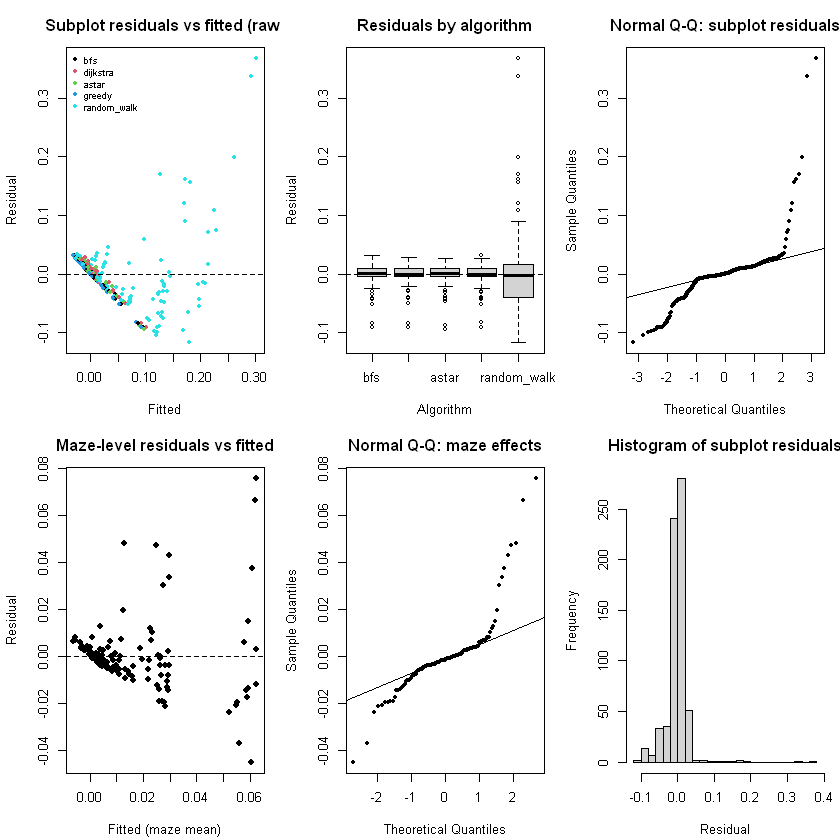

In [30]:
# ---- 1a. Check the untransformed response ------------------------------------
check_model(dat$y_raw, dat, "(raw)")                  # shows in the Plots pane
dev.copy(png, "diag_raw.png", width = 1500, height = 900, res = 120); dev.off()


agg_record_458638957 
                   2


Box-Cox: lambda_hat = -0.160, 95% CI = (-0.186, -0.133)


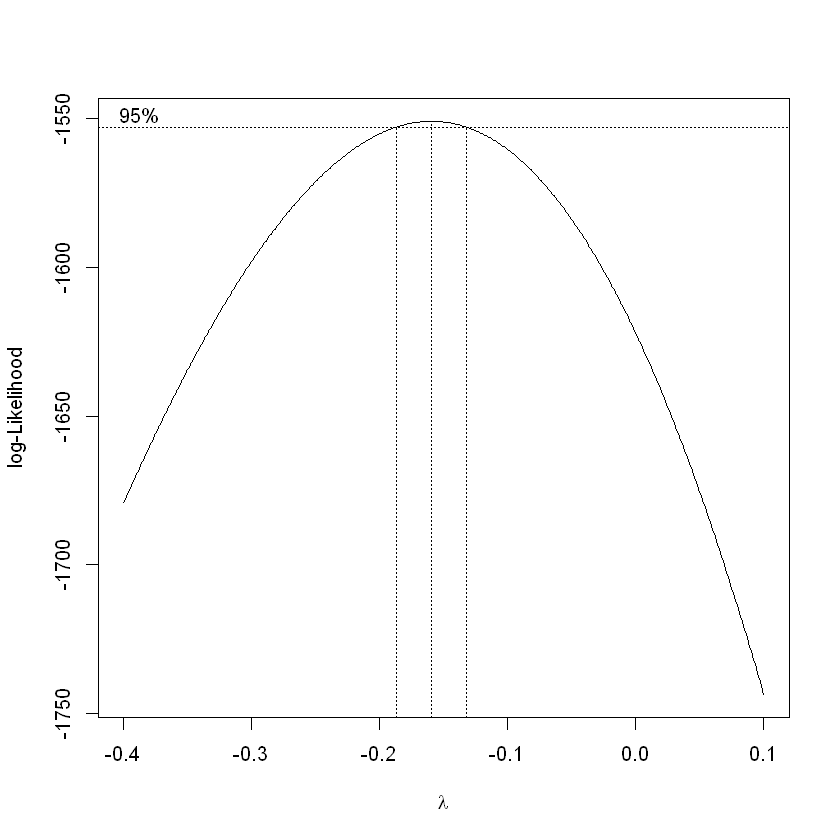

In [31]:
# ---- 2. Box-Cox --------------------------------------------------------------
fit_bc <- lm(y_raw ~ maze + A + A:S + A:D + A:G, data = dat)

png("boxcox.png", width = 1000, height = 600, res = 120)
bc <- boxcox(fit_bc, lambda = seq(-0.4, 0.1, by = 0.001))
dev.off()
bc <- boxcox(fit_bc, lambda = seq(-0.4, 0.1, by = 0.001))  # also show on screen

lambda_hat <- bc$x[which.max(bc$y)]
ci <- range(bc$x[bc$y > max(bc$y) - qchisq(0.95, 1) / 2])
cat(sprintf("\nBox-Cox: lambda_hat = %.3f, 95%% CI = (%.3f, %.3f)\n",
            lambda_hat, ci[1], ci[2]))


--- Diagnostics (transformed) ---
Shapiro-Wilk (subplot residuals): p = 6.15e-08 
Shapiro-Wilk (maze-level residuals): p = 0.183 
Fligner-Killeen (equal variance across algorithms): p = 2.55e-14 
Residual SD by algorithm:
        bfs    dijkstra       astar      greedy random_walk 
     0.7302      0.6775      0.9662      0.8520      1.4063 


png 
  3

agg_record_2022378745 
                    2

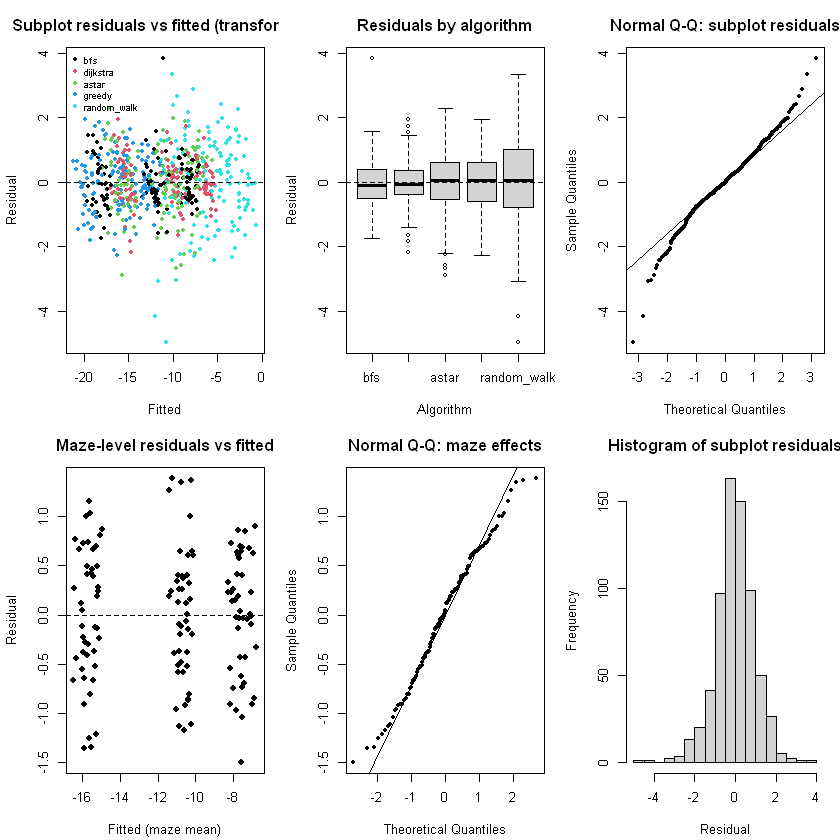

In [32]:
# ---- 3. Transform and recheck ------------------------------------------------
bc_transform <- function(y, lambda) if (lambda == 0) log(y) else (y^lambda - 1) / lambda
dat$y_t <- bc_transform(dat$y_raw, lambda)

check_model(dat$y_t, dat, "(transformed)")
dev.copy(png, "diag_transformed.png", width = 1500, height = 900, res = 120); dev.off()
# If the transformed plots are not clearly better, set dat$y_t <- dat$y_raw here.


In [33]:

# ---- 4. Split-plot ANOVA -----------------------------------------------------
fit <- aov(y_t ~ R + G + S + D + S:D + A + S:A + D:A + G:A + Error(maze), data = dat)
cat("\n===== Split-plot ANOVA =====\n")
print(summary(fit))
# Error: maze    -> R, G, S, D, S:D tested against the maze error (120 df).
#                   (the F for R, the block, is not meaningful; ignore it)
# Error: Within  -> A, S:A, D:A, G:A tested against the subplot error (512 df).

# Reference check (optional): full model with every G/S/D/A interaction
# summary(aov(y_t ~ R + G*S*D*A + Error(maze), data = dat))


===== Split-plot ANOVA =====

Error: maze
           Df Sum Sq Mean Sq  F value   Pr(>F)    
R           4      7       2    0.771  0.54620    
G           2     30      15    6.286  0.00253 ** 
S           2   7433    3717 1559.276  < 2e-16 ***
D           2     49      25   10.330 7.25e-05 ***
S:D         4      7       2    0.692  0.59909    
Residuals 120    286       2                      
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Error: Within
           Df Sum Sq Mean Sq  F value   Pr(>F)    
A           4   7378  1844.5 1522.361  < 2e-16 ***
S:A         8    222    27.7   22.859  < 2e-16 ***
D:A         8     91    11.3    9.342 4.56e-12 ***
G:A         8     38     4.8    3.959 0.000146 ***
Residuals 512    620     1.2                      
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


png 
  3

agg_record_618198005 
                   2

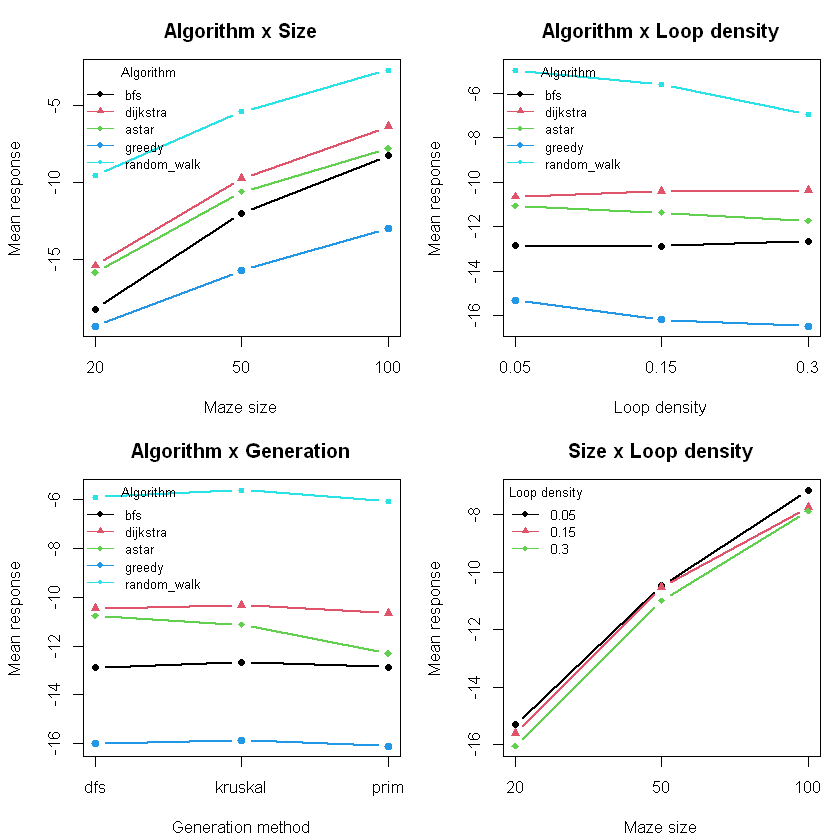

In [34]:
# ---- 5. Interaction plots ----------------------------------------------------
# Cell means of the analysed response (y_t). Rows = x-axis levels, lines = trace.
ia_plot <- function(x, trace, resp, xlab, tracelab, main) {
  m <- tapply(resp, list(x, trace), mean)
  k <- ncol(m)
  matplot(seq_len(nrow(m)), m, type = "b", lty = 1, pch = 15 + seq_len(k),
          col = seq_len(k), lwd = 2, xaxt = "n", xlab = xlab,
          ylab = "Mean response", main = main)
  axis(1, at = seq_len(nrow(m)), labels = rownames(m))
  legend("topleft", legend = colnames(m), title = tracelab,
         col = seq_len(k), pch = 15 + seq_len(k), lty = 1, cex = 0.8, bty = "n")
}

ylab_resp <- if (lambda == 0) "log(frac explored)" else
  if (lambda == 1) "frac explored" else "transformed frac explored"

op <- par(mfrow = c(2, 2), mar = c(4.2, 4.2, 3, 1))
ia_plot(dat$S, dat$A, dat$y_t, "Maze size", "Algorithm",  "Algorithm x Size")
ia_plot(dat$D, dat$A, dat$y_t, "Loop density", "Algorithm", "Algorithm x Loop density")
ia_plot(dat$G, dat$A, dat$y_t, "Generation method", "Algorithm", "Algorithm x Generation")
ia_plot(dat$S, dat$D, dat$y_t, "Maze size", "Loop density", "Size x Loop density")
par(op)
dev.copy(png, "interaction_plots.png", width = 1500, height = 1100, res = 120); dev.off()
# Roughly parallel lines = no interaction; crossing or fanning lines = interaction.

In [35]:
# ---- 6. Algorithm means ------------------------------------------------------
cat("\nMean response by algorithm (analysis scale):\n")
print(round(sort(tapply(dat$y_t, dat$A, mean)), 3))
cat("\nMean fraction of maze explored by algorithm (original scale):\n")
print(round(sort(tapply(dat$y_raw, dat$A, mean)), 4))
cat("\nSuccess rate by algorithm:\n")
print(round(tapply(dat$success, dat$A, mean), 3))



Mean response by algorithm (analysis scale):
     greedy         bfs       astar    dijkstra random_walk 
    -15.991     -12.801     -11.394     -10.481      -5.849 

Mean fraction of maze explored by algorithm (original scale):
     greedy         bfs       astar    dijkstra random_walk 
     0.0004      0.0019      0.0031      0.0047      0.0664 

Success rate by algorithm:
        bfs    dijkstra       astar      greedy random_walk 
      1.000       1.000       1.000       1.000       0.985 
